# Lab 1: Vacuum Cleaner Agent (4 rooms)
Environment (Anaconda): `conda create -n ailab python=3.11 numpy matplotlib jupyter`, then `conda activate ailab` and `jupyter notebook`.

Run cells top to bottom with **Shift+Enter**.

**PEAS:** performance = +1 per clean room per step; environment = 4 rooms with random dirt; actuators = Left/Right/Suck/NoOp; sensors = (position, status).

## Cell 1: Setup (ready-made libraries)

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_ROOMS = 4     # number of rooms
STEPS = 50      # steps in one run
RUNS = 100      # number of experiments per agent

## Cell 2: One simple function

In [47]:
def simulate(agent, seed):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5               # True = dirty room
    known_clean = np.zeros(N_ROOMS, dtype=bool)    # memory of the "model" agent
    pos, direction, score = 0, 1, 0

    for step in range(STEPS):
        dirtification = rng.random(N_ROOMS) < 0.2
        dirt |= dirtification
        known_clean = np.zeros(N_ROOMS, dtype=bool)
        known_clean[pos] = not dirt[pos]

        # 1) choose an action
        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        # 2) apply the action
        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += (~dirt).sum()                     # +1 for each clean room
    return int(score)

## Cell 3: Quick test of the 3 agents

In [48]:
for agent in ["random", "reflex", "model"]:
    print(agent, simulate(agent, seed=1))

random 57
reflex 107
model 115


## Cell 4: 100 experiments (pandas)

In [49]:
rows = []
for agent in ["random", "reflex", "model"]:
    for seed in range(RUNS):
        rows.append({"agent": agent, "score": simulate(agent, seed)})

df = pd.DataFrame(rows)
print(df.head())

    agent  score
0  random     52
1  random     57
2  random     61
3  random     70
4  random     79


## Cell 5: Summary table

In [50]:
summary = df.groupby("agent")["score"].agg(["mean", "std"]).round(1)
print(summary)

         mean   std
agent              
model   119.7  12.1
random   53.7  16.1
reflex   99.2  11.6


## Cell 6: Plot

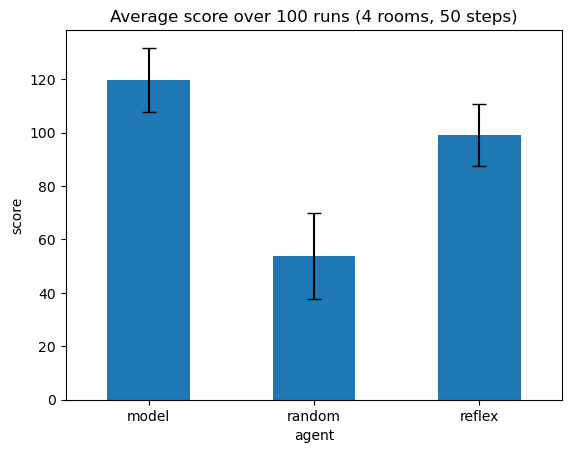

In [51]:
summary["mean"].plot(kind="bar", yerr=summary["std"], capsize=5)
plt.title("Average score over 100 runs (4 rooms, 50 steps)")
plt.ylabel("score")
plt.xticks(rotation=0)
plt.show()

## Analysis questions
1. Why is the random agent weak?
2. Why does the model-based agent stop?
3. What if dirt reappears with probability p?

## Challenges
2D grid, noisy sensor, energy cost, dirt reappearing.

## Cell 7: Record frames for animation

This function follows the same agent rules as `simulate`, but saves the room state after every step so it can be animated.

In [52]:
def record(agent, seed=1):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5
    known_clean = np.zeros(N_ROOMS, dtype=bool)
    pos, direction, score = 0, 1, 0
    frames = [(pos, dirt.copy(), "Start", score)]

    for step in range(STEPS):
        dirtification = rng.random(N_ROOMS) < 0.2
        dirt |= dirtification
        known_clean = np.zeros(N_ROOMS, dtype=bool)
        known_clean[pos] = not dirt[pos]

        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += int((~dirt).sum())
        frames.append((pos, dirt.copy(), action, score))

    return frames


## Cell 8: Animate the three agents

Each row shows one agent moving through the same initial room layout. Red rooms are dirty; green rooms are clean.

In [53]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

names = ["random", "reflex", "model"]
runs = [record(agent, seed=1) for agent in names]

fig, axes = plt.subplots(3, 1, figsize=(7, 4.5), dpi=80)

def draw(t):
    for ax, name, frames in zip(axes, names, runs):
        pos, dirt_state, action, score = frames[t]
        ax.clear()
        ax.set_xlim(0, N_ROOMS)
        ax.set_ylim(0, 1)
        ax.axis("off")

        for room in range(N_ROOMS):
            color = "#fecaca" if dirt_state[room] else "#bbf7d0"
            ax.add_patch(plt.Rectangle((room + 0.05, 0.05), 0.9, 0.9, color=color))
            if dirt_state[room]:
                ax.add_patch(plt.Circle((room + 0.5, 0.35), 0.13, color="#38bdf8"))

        ax.text(pos + 0.5, 0.68, "R", fontsize=19, fontweight="bold",
                ha="center", va="center")
        ax.set_title(f"{name} | step {t} | action: {action} | score: {score}", fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(runs[0]), interval=250, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())


## Cell 9: Animated bar chart of average scores

This animation grows the bars toward the final mean scores computed in Cell 5.

In [54]:
fig2, ax2 = plt.subplots(figsize=(6, 3.5), dpi=80)
final = summary["mean"]

def grow(k):
    ax2.clear()
    ax2.set_ylim(0, max(210, float(final.max()) * 1.15))
    ax2.set_title("Average score over 100 runs")
    ax2.set_ylabel("Score")
    values = final.values * (k + 1) / 20
    bars = ax2.bar(final.index, values, color=["#ec4899", "#4f46e5", "#f59e0b"])
    for bar, value in zip(bars, values):
        ax2.text(bar.get_x() + bar.get_width() / 2, value + 2,
                 f"{value:.1f}", ha="center", va="bottom")
    ax2.set_xticks(range(len(final.index)), final.index, rotation=0)

anim2 = FuncAnimation(fig2, grow, frames=20, interval=120, repeat=False)
plt.close(fig2)
HTML(anim2.to_jshtml())
